# [RQ_2 · HỖ TRỢ] Thí nghiệm 01 · Hai baseline cho Config C

Mục tiêu là xác định điểm đối chứng cho các mô hình dự đoán lưu lượng theo giờ. Baseline thứ–giờ dùng trung bình lịch sử của từng nhóm ngày trong tuần và giờ trong ngày. Seasonal naive dự đoán bằng lưu lượng quan sát đúng 168 giờ trước.

```mermaid
flowchart LR
    A[CSV gốc theo thời gian] --> B[Gộp timestamp và chia tập]
    B --> C[Điền thời tiết bằng thống kê từ train]
    C --> D[Tạo lịch sử chỉ từ giờ trước]
    D --> E[Lọc đủ lịch sử trên train và validation]
    E --> F[Trung bình thứ–giờ và lag 168 giờ]
    F --> G[Chấm MAE, RMSE và R² trên cùng giờ validation]
```

Đánh giá từng giờ theo thứ tự thời gian. Seasonal naive giả định lưu lượng quan sát của những giờ trước đã có khi dự đoán. Các giờ thiếu một trong ba đặc trưng của Config C bị loại ở cả hai tập được so sánh. Tập test được giữ lại cho đánh giá cuối.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


In [1]:
from hashlib import file_digest, sha256
import json
from pathlib import Path
import sys

start = Path.cwd().resolve()
project = next(path for path in (start, *start.parents) if (path / "src/data.py").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from IPython.display import Image, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
import sklearn

from src.data import DATA_PATH, fill_missing_weather
from src.evaluation import regression_metrics, seasonal_naive, weekday_hour_baseline
from src.features import HISTORY_FEATURES, has_history, build_features

experiment = project / "experiments/17-11-2026_Huy_ConfigC/01_baselines"
data_path = DATA_PATH if DATA_PATH.is_file() else project / "files/Metro_Interstate_Traffic_Volume.csv.gz"
data_params = {"mask_stuck_temp": False, "complete_holidays": False}

In [2]:
from src.experiment_data import load_experiment_splits
raw_splits = load_experiment_splits(data_path, **data_params, stage="raw")
development = {name: raw_splits[name] for name in ("train", "validation")}
featured = build_features(fill_missing_weather(development))
eligible = {name: frame.loc[has_history(frame)].copy() for name, frame in featured.items()}
train = eligible["train"]
validation = eligible["validation"]

for name, frame in eligible.items():
    timestamps = frame["date_time"]
    if frame.empty or timestamps.hasnans or not timestamps.is_unique or not timestamps.is_monotonic_increasing:
        raise ValueError(f"Tập {name} phải có timestamp đầy đủ, duy nhất và tăng dần.")
if train["date_time"].max() >= validation["date_time"].min():
    raise ValueError("Train phải kết thúc trước validation.")

volume_by_timestamp = (
    pd.concat(development.values(), ignore_index=True)
    .set_index("date_time", verify_integrity=True)["traffic_volume"]
)
lag_timestamps = validation["date_time"] - pd.Timedelta(hours=168)
expected_lag = lag_timestamps.map(volume_by_timestamp).astype("float64")
pd.testing.assert_series_equal(validation["lag_168h"], expected_lag, check_names=False)

coverage = pd.DataFrame([
    {
        "split": name,
        "all_hours": len(frame),
        "eligible_hours": len(eligible[name]),
        "excluded_hours": len(frame) - len(eligible[name]),
        "eligible_start": str(eligible[name]["date_time"].min()),
        "eligible_end": str(eligible[name]["date_time"].max()),
    }
    for name, frame in development.items()
])
display(coverage)

cell 2:17: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.


,split,all_hours,eligible_hours,excluded_hours,eligible_start,eligible_end
0,train,28402,22503,5899,2012-10-09 09:00:00,2017-05-10 04:00:00
1,validation,6086,6050,36,2017-05-10 05:00:00,2018-01-19 14:00:00


In [3]:
predictions = validation[["date_time", "traffic_volume", "is_rush_hour"]].copy()
predictions["baseline_weekday_hour"] = weekday_hour_baseline(train, validation)
predictions["baseline_seasonal_naive"] = seasonal_naive(validation)
models = ["baseline_weekday_hour", "baseline_seasonal_naive"]

def score(frame):
    """Tính điểm cho cả hai baseline trên cùng các dòng của một nhóm."""
    return pd.DataFrame([
        {
            "model": model,
            "n_validation": len(frame),
            **regression_metrics(frame["traffic_volume"], frame[model]),
        }
        for model in models
    ])

metrics = score(predictions)
slice_frames = []
for label, is_rush in (("rush_hour", True), ("non_rush_hour", False)):
    subset = predictions.loc[predictions["is_rush_hour"].eq(is_rush)]
    slice_metrics = score(subset)
    slice_metrics.insert(1, "slice", label)
    slice_frames.append(slice_metrics)
slices = pd.concat(slice_frames, ignore_index=True)
display(metrics.round(4))
display(slices.round(4))

,model,n_validation,MAE,RMSE,R2
0,baseline_weekday_hour,6050,291.7388,503.2185,0.9344
1,baseline_seasonal_naive,6050,330.1775,635.0735,0.8955


,model,slice,n_validation,MAE,RMSE,R2
0,baseline_weekday_hour,rush_hour,1080,494.5163,847.4033,0.1482
1,baseline_seasonal_naive,rush_hour,1080,587.9694,1130.0378,-0.5148
2,baseline_weekday_hour,non_rush_hour,4970,247.6745,390.1439,0.9490
3,baseline_seasonal_naive,non_rush_hour,4970,274.1584,462.0250,0.9285


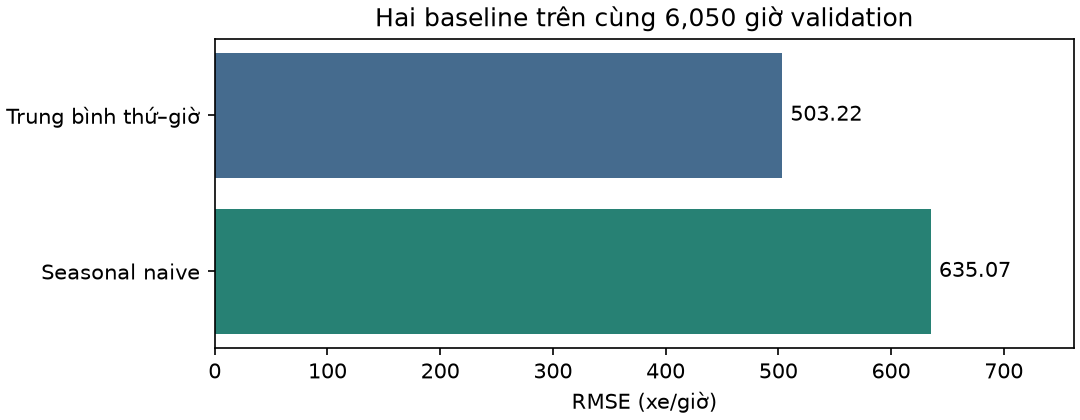

In [4]:
output_dir = experiment / "outputs"
figure_dir = experiment / "figures"
output_dir.mkdir(exist_ok=True)
figure_dir.mkdir(exist_ok=True)
predictions[["date_time", "traffic_volume", *models, "is_rush_hour"]].to_csv(
    output_dir / "validation_predictions.csv", index=False
)
metrics.to_csv(output_dir / "validation_metrics.csv", index=False)
slices.to_csv(output_dir / "validation_slices.csv", index=False)
coverage.to_csv(output_dir / "coverage.csv", index=False)

with data_path.open("rb") as stream:
    data_digest = file_digest(stream, "sha256").hexdigest()
timestamp_text = "\n".join(predictions["date_time"].dt.strftime("%Y-%m-%d %H:%M:%S"))
config = {
    "data": data_path.relative_to(project).as_posix(),
    "data_sha256": data_digest,
    "data_params": data_params,
    "history_features_required": list(HISTORY_FEATURES),
    "evaluation": "validation",
    "eligibility": coverage.to_dict("records"),
    "validation_timestamp_sha256": sha256(timestamp_text.encode("utf-8")).hexdigest(),
    "versions": {"pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(output_dir / "run_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)

labels = ["Trung bình thứ–giờ", "Seasonal naive"]
fig, ax = plt.subplots(figsize=(7.2, 2.8), layout="constrained")
bars = ax.barh(labels, metrics["RMSE"], color=["#456B8E", "#278174"])
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, metrics["RMSE"].max() * 1.2)
ax.set_xlabel("RMSE (xe/giờ)")
ax.set_title(f"Hai baseline trên cùng {len(validation):,} giờ validation")
figure = figure_dir / "validation_rmse.png"
fig.savefig(figure, dpi=150)
plt.close(fig)
display(Image(filename=str(figure)))

<!-- proposal-assessment -->
## Đánh giá đối với proposal — RQ_2

**Vai trò: HỖ TRỢ.** Mã đối chiếu: [E19](../../../docs/experiment_tracking/EXPERIMENTS_BY_DATE_AND_RQ.md). 

- **Câu hỏi:** Seasonal naive có vượt trung bình thứ–giờ khi chấm đúng cùng giờ đủ lịch sử không?
- **Đánh giá:** Cung cấp baseline chung cho mở rộng history: trên 6.050 giờ, trung bình thứ–giờ có RMSE 503,219 tốt hơn seasonal naive 635,073. Các mô hình C cần được so với cả hai mốc trên chính cohort này.
- **Giới hạn kết luận:** Đây là baseline hỗ trợ, không phải bằng chứng một thuật toán học máy thắng hoặc lịch sử tự động có ích. Seasonal naive yêu cầu lưu lượng tuần trước đã có lúc dự đoán.
- **Bằng chứng:** [E19: validation_metrics.csv](outputs/validation_metrics.csv).

Đánh giá trên dựa vào hiện vật lịch sử đã đối chứng, không phải kết quả chạy mới. Code lấy dữ liệu đã được chuẩn hóa; chưa huấn luyện lại hoặc chấm test.
